# Simulations of the Heisenberg model alone

* Linear sizes of the cluster must be multiples of 3 to be compatible with the $120^\circ$ Néel order.
* Starting a simulation from a $120^\circ$ Néel state (with $\chi=\pm1$) results in small thermal fluctuations around this state throughout the simulation.
* It is possible to arrive at the $120^\circ$ Néel state starting from a randomized state after a sufficiently high number of steps.
* Specific heat can be directly measured as $c_V = \frac{d\langle E\rangle}{dT} = \frac{1}{kT^2} \left[\langle E^2\rangle - \langle E\rangle^2\right]$.
* Idea: Try to suppress domain walls and to speed up convergence towards the $120^\circ$ Néel state by using reweighting with $w(\phi) = e^{\alpha \sum_i(1 - \chi_i^2)}$.

In [ ]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice
using MX2RKKY.observables
using MX2RKKY.visualization: plot_conf

using Random: MersenneTwister
using Makie

using MPI
MPI.Init();

In [3]:
# Cluster size
L1, L2 = 27, 27

# Heisenberg parameters
J = 1.0
# RKKY parameters
V = 0.0
λ = 0.1 # k_F a_0

0.1

## Energy and chirality evolution at low temperature

120° Néel state as initial state ($\chi=-1$)

In [4]:
T = 0.01

n_mcs = 200000
n_warmup_mcs = 0

conf = Configuration(L1, L2, -1)
sim = MCSimulation(conf, MersenneTwister(123456), β=1/T, J=J, V=V, λ=λ)
acceptance_rate = run!(sim, n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)
@show acceptance_rate

[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:04:33m


acceptance_rate = 0.029371467764060355


0.029371467764060355

In [5]:
@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)
@show specific_heat(sim) / (L1 * L2)
@show avg_chirality(sim)
@show var_chirality(sim)
@show susc_chirality(sim) / (L1 * L2)
@show binder_chirality(sim)
@show corr_length_chirality(sim)
@show susc_spin_K(sim) / (L1 * L2)
@show binder_spin_K(sim)
@show corr_length_spin_K(sim)

min_energy(sim) / (L1 * L2) = -1.4998845592863261
avg_energy(sim) / (L1 * L2) = -1.4949943531904548
var_energy(sim) / (L1 * L2) = 0.0002695095144992592
specific_heat(sim) / (L1 * L2) = 0.5295119085770165
avg_chirality(sim) = -1.0
var_chirality(sim) = 0.0
susc_chirality(sim) / (L1 * L2) = 0.0
binder_chirality(sim) = 0.75
corr_length_chirality(sim) = 1.1498434481061173e17 - 0.0im
susc_spin_K(sim) / (L1 * L2) = 0.31432627338988406
binder_spin_K(sim) = 0.9999988657825585
corr_length_spin_K(sim) = 284.89691983211117 + 0.0im


284.89691983211117 + 0.0im

120° Néel state as initial state ($\chi=1$)

In [5]:
T = 0.01

n_mcs = 200000
n_warmup_mcs = 0

conf = Configuration(L1, L2, 1)
sim = MCSimulation(conf, MersenneTwister(123456), β=1/T, J=J, V=V, λ=λ)
acceptance_rate = run!(sim, n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)
@show acceptance_rate

[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:04:32


acceptance_rate = 0.02935923182441701


0.02935923182441701

In [6]:
@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)
@show specific_heat(sim) / (L1 * L2)
@show avg_chirality(sim)
@show var_chirality(sim)
@show susc_chirality(sim) / (L1 * L2)
@show binder_chirality(sim)
@show corr_length_chirality(sim)
@show susc_spin_K(sim) / (L1 * L2)
@show binder_spin_K(sim)
@show corr_length_spin_K(sim)

min_energy(sim) / (L1 * L2) = -1.4998850821603658
avg_energy(sim) / (L1 * L2) = -1.4950007555978642
var_energy(sim) / (L1 * L2) = 0.00026773246628680167
specific_heat(sim) / (L1 * L2) = 0.5225521098442576
avg_chirality(sim) = 1.0
var_chirality(sim) = 0.0
susc_chirality(sim) / (L1 * L2) = 0.0
binder_chirality(sim) = 0.75
corr_length_chirality(sim) = 1.1224194802655168e17 - 0.0im
susc_spin_K(sim) / (L1 * L2) = 1.411007106103326
binder_spin_K(sim) = 0.9999988511171967
corr_length_spin_K(sim) = 289.6075439442655 + 0.0im


289.6075439442655 + 0.0im

Random initial state

In [7]:
T = 0.01

n_mcs = 200000
n_warmup_mcs = 0

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, rng)
sim = MCSimulation(conf, rng, β=1/T, J=J, V=V, λ=λ)
acceptance_rate = run!(sim, n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)
@show acceptance_rate

[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:04:34


acceptance_rate = 0.030981104252400547


0.030981104252400547

min_energy(sim) / (L1 * L2) = -1.4377289790948498
avg_energy(sim) / (L1 * L2) = -1.4058184143693635
var_energy(sim) / (L1 * L2) = 0.019325146769110898
specific_heat(sim) / (L1 * L2) = 27.225328598515684
avg_chirality(sim) = 0.5087136533334657
var_chirality(sim) = 0.18822783954608746
susc_chirality(sim) / (L1 * L2) = 0.35429719580187646
binder_chirality(sim) = 0.33942414613401434
susc_spin_K(sim) / (L1 * L2) = 0.38331628744935364
binder_spin_K(sim) = 0.9621749738112761
corr_length_spin_K(sim) = 21.390691385074426 + 0.0im


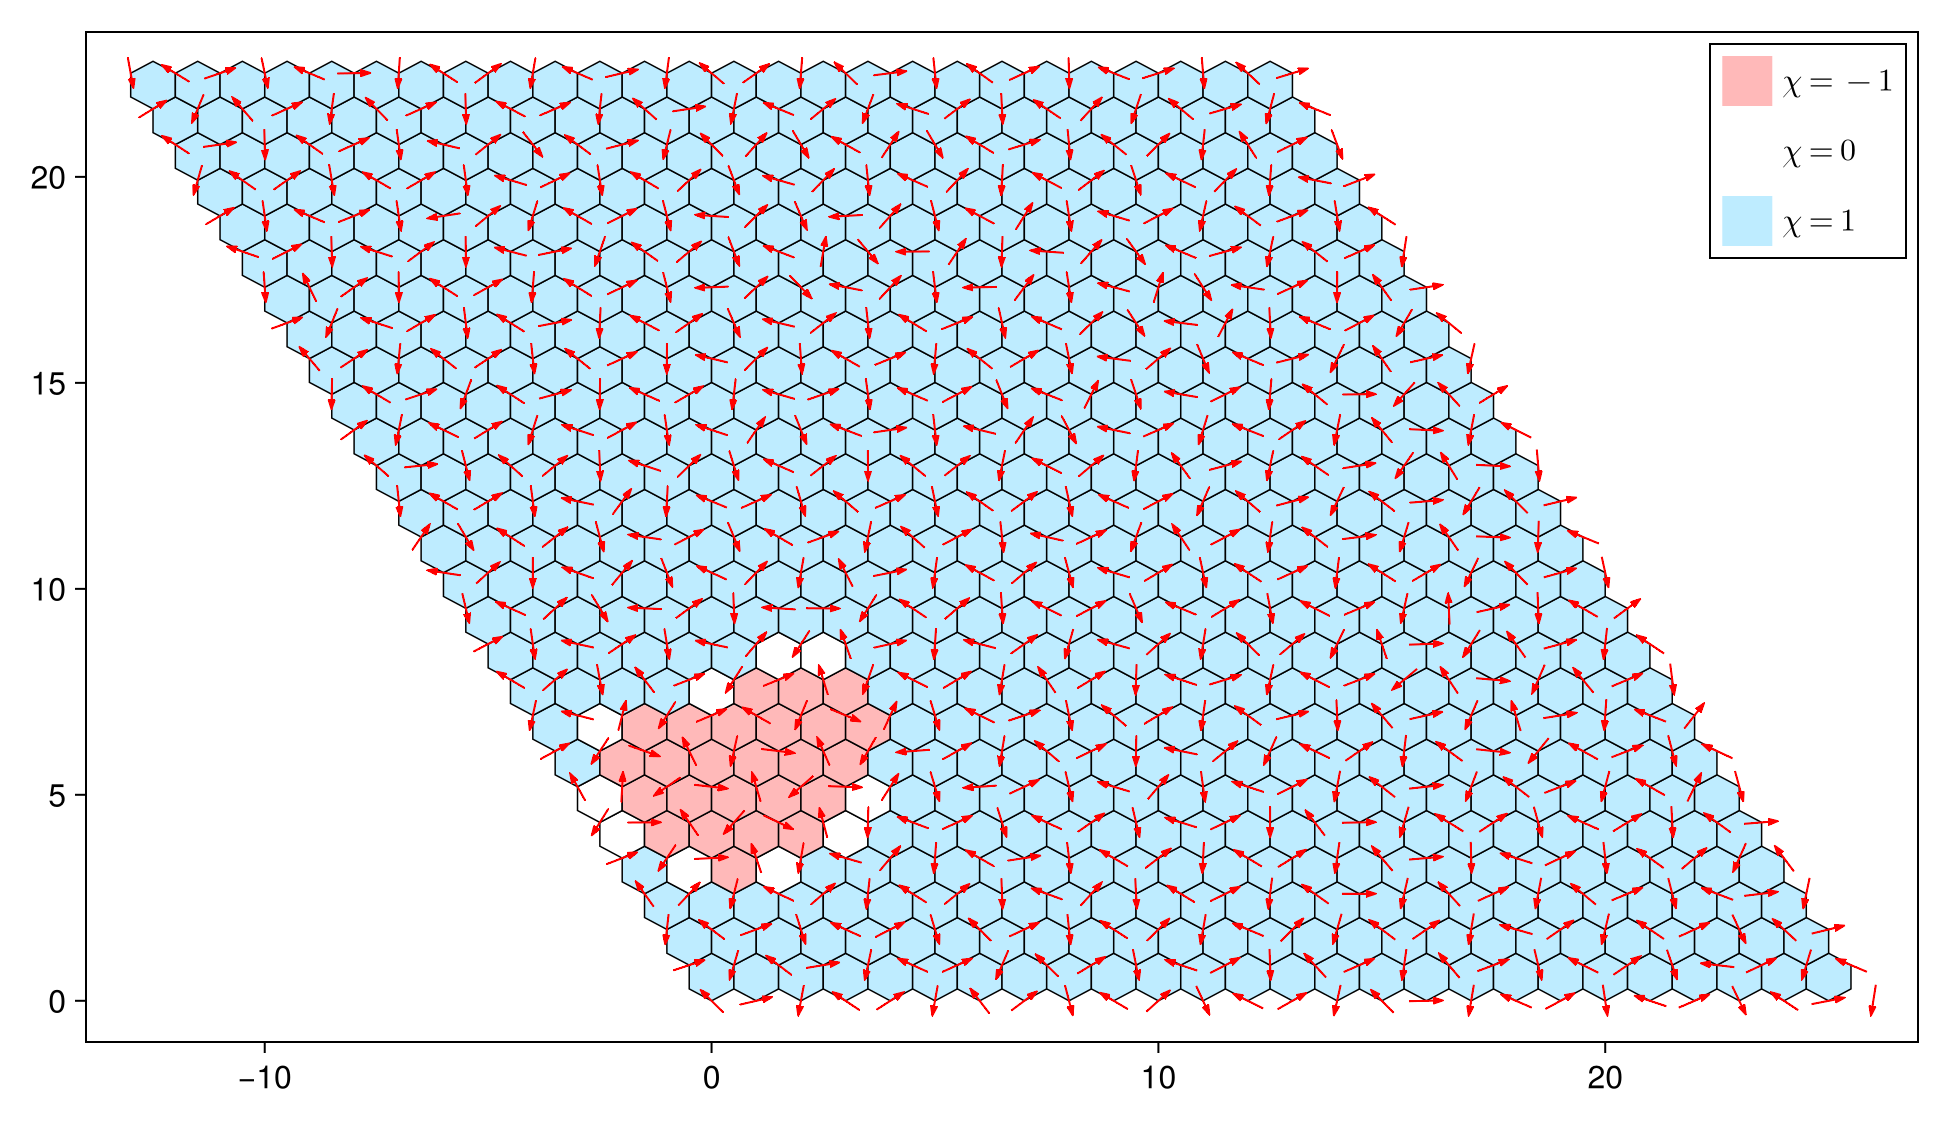

In [13]:
@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)
@show specific_heat(sim) / (L1 * L2)
@show avg_chirality(sim)
@show var_chirality(sim)
@show susc_chirality(sim) / (L1 * L2)
@show binder_chirality(sim)
#@show corr_length_chirality(sim)
@show susc_spin_K(sim) / (L1 * L2)
@show binder_spin_K(sim)
@show corr_length_spin_K(sim)

fig = plot_conf(sim.conf)
save("heisenberg_conf_T0.01.pdf", fig);
fig

Random initial state, higher temperature

In [14]:
T = 0.1

n_mcs = 250000
n_warmup_mcs = 0

rng = MersenneTwister(127459)
conf = Configuration(L1, L2, rng)
sim = MCSimulation(conf, rng, β=1/T, J=J, V=V, λ=λ)
acceptance_rate = run!(sim, n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)
@show acceptance_rate

[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:05:45


acceptance_rate = 0.09503497942386831


0.09503497942386831

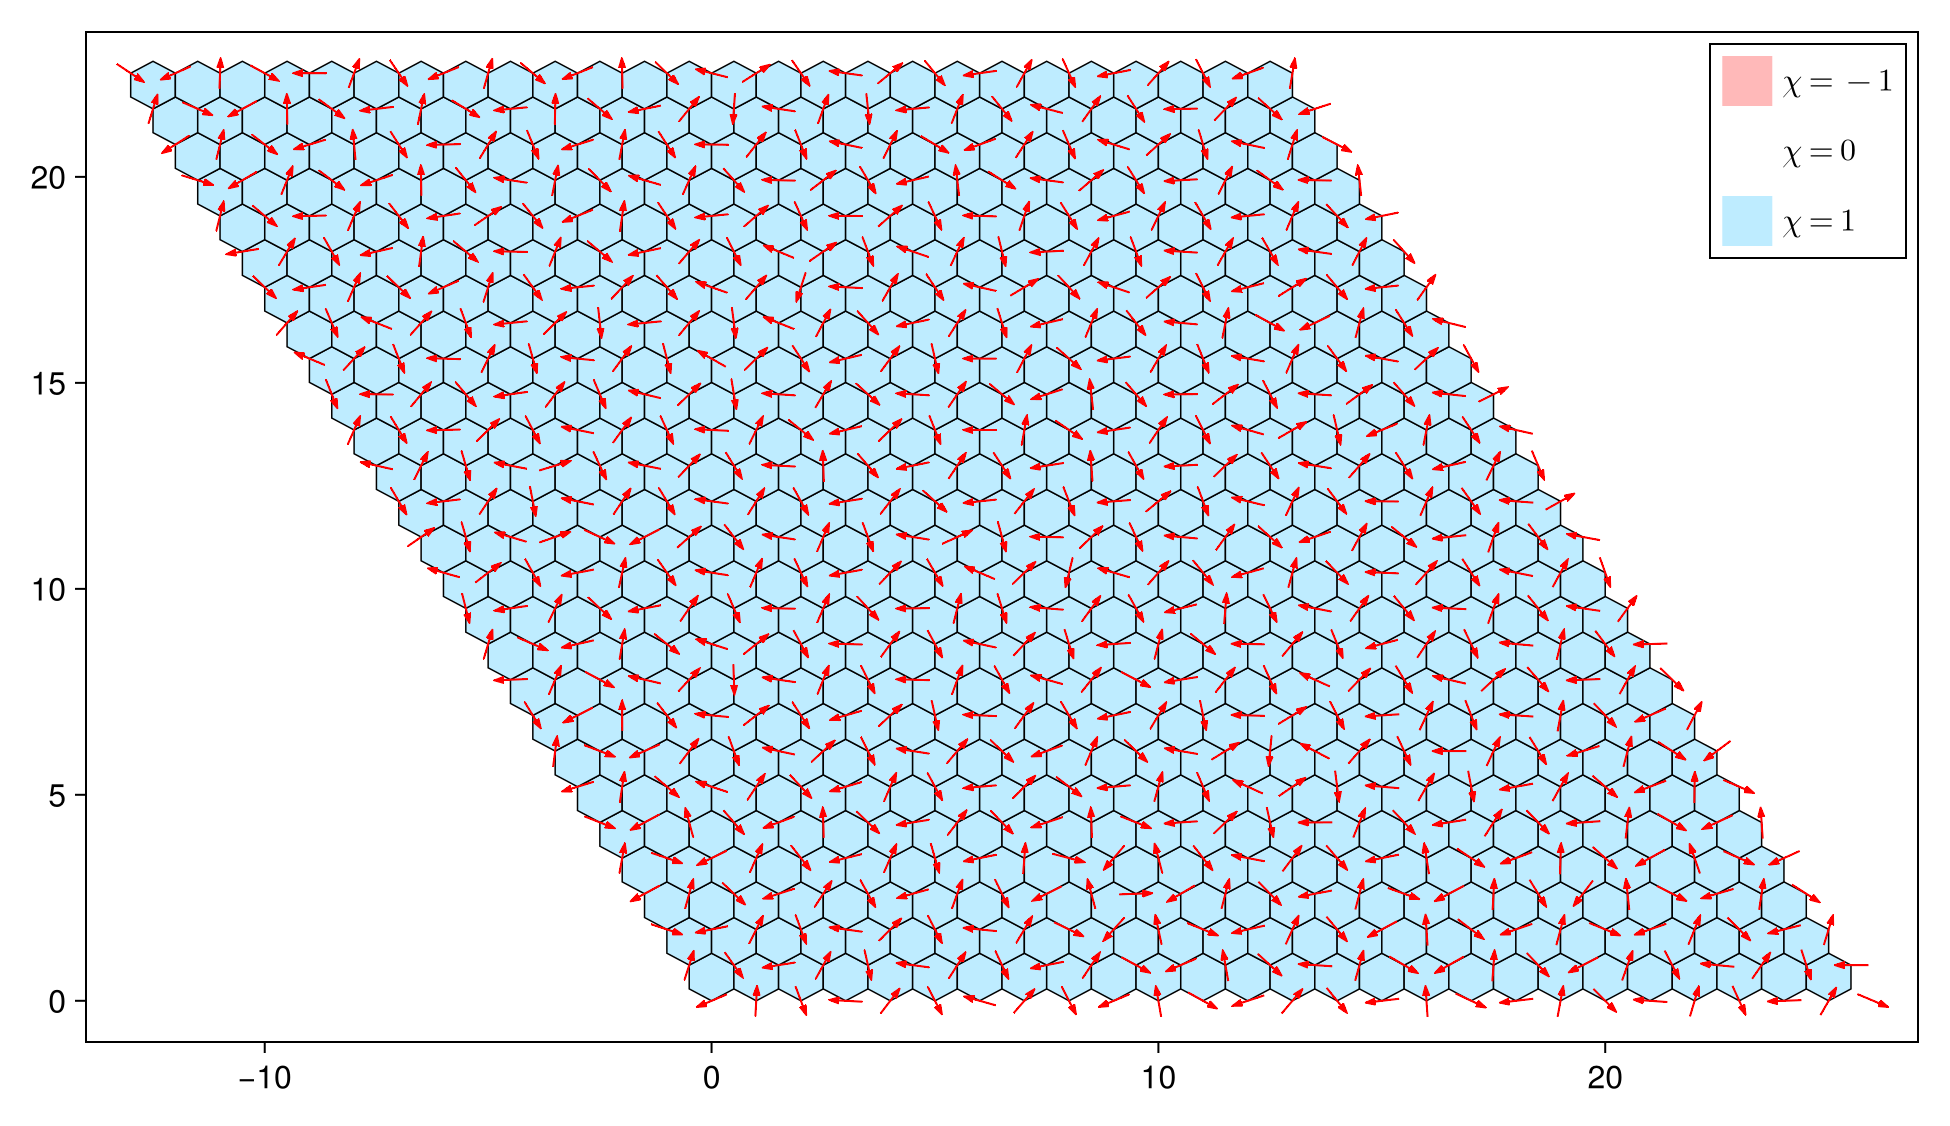

In [15]:
fig = plot_conf(sim.conf);
save("heisenberg_conf_T0.1.pdf", fig)
fig

## Temperature scan

In [115]:
# Cluster size
L1, L2 = 27, 27

# Heisenberg parameter
J = 1.0
# RKKY parameters
V = 0.0
λ = 0.1

# Temperature range
T_range = 0.05:0.05:2.0

n_mcs = 50_000
n_warmup_mcs = 10_000

E_avg = Float64[]
E_err = Float64[]
cV = Float64[]

χ_avg = Float64[]
χ_err = Float64[]
χ_susc = Float64[]
χ_binder = Float64[]

m_susc = Float64[]
m_binder = Float64[]

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, 1)

for (n, T) in enumerate(T_range)
    @show T
    sim = MCSimulation(conf, rng, β=1/T, J=J, V=V, λ=λ)
    acceptance_rate = run!(sim, n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)
    @show acceptance_rate

    push!(E_avg, avg_energy(sim))
    push!(E_err, err_energy(sim))
    push!(cV, specific_heat(sim))
    push!(χ_avg, avg_chirality(sim))
    push!(χ_err, err_chirality(sim))
    push!(χ_susc, susc_chirality(sim))
    push!(χ_binder, binder_chirality(sim))
    push!(m_susc, susc_spin_K(sim))
    push!(m_binder, binder_spin_K(sim))

    conf = deepcopy(sim.conf)
end

T = 0.05


[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:01:28


acceptance_rate = 0.06623971193415638
T = 0.1


[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:01:30


acceptance_rate = 0.09472551440329217
T = 0.15


[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:01:29


... (71 outputs left out)

[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:01:51


acceptance_rate = 0.6540935756744398
T = 2.0


[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:01:51


acceptance_rate = 0.6603794924554184


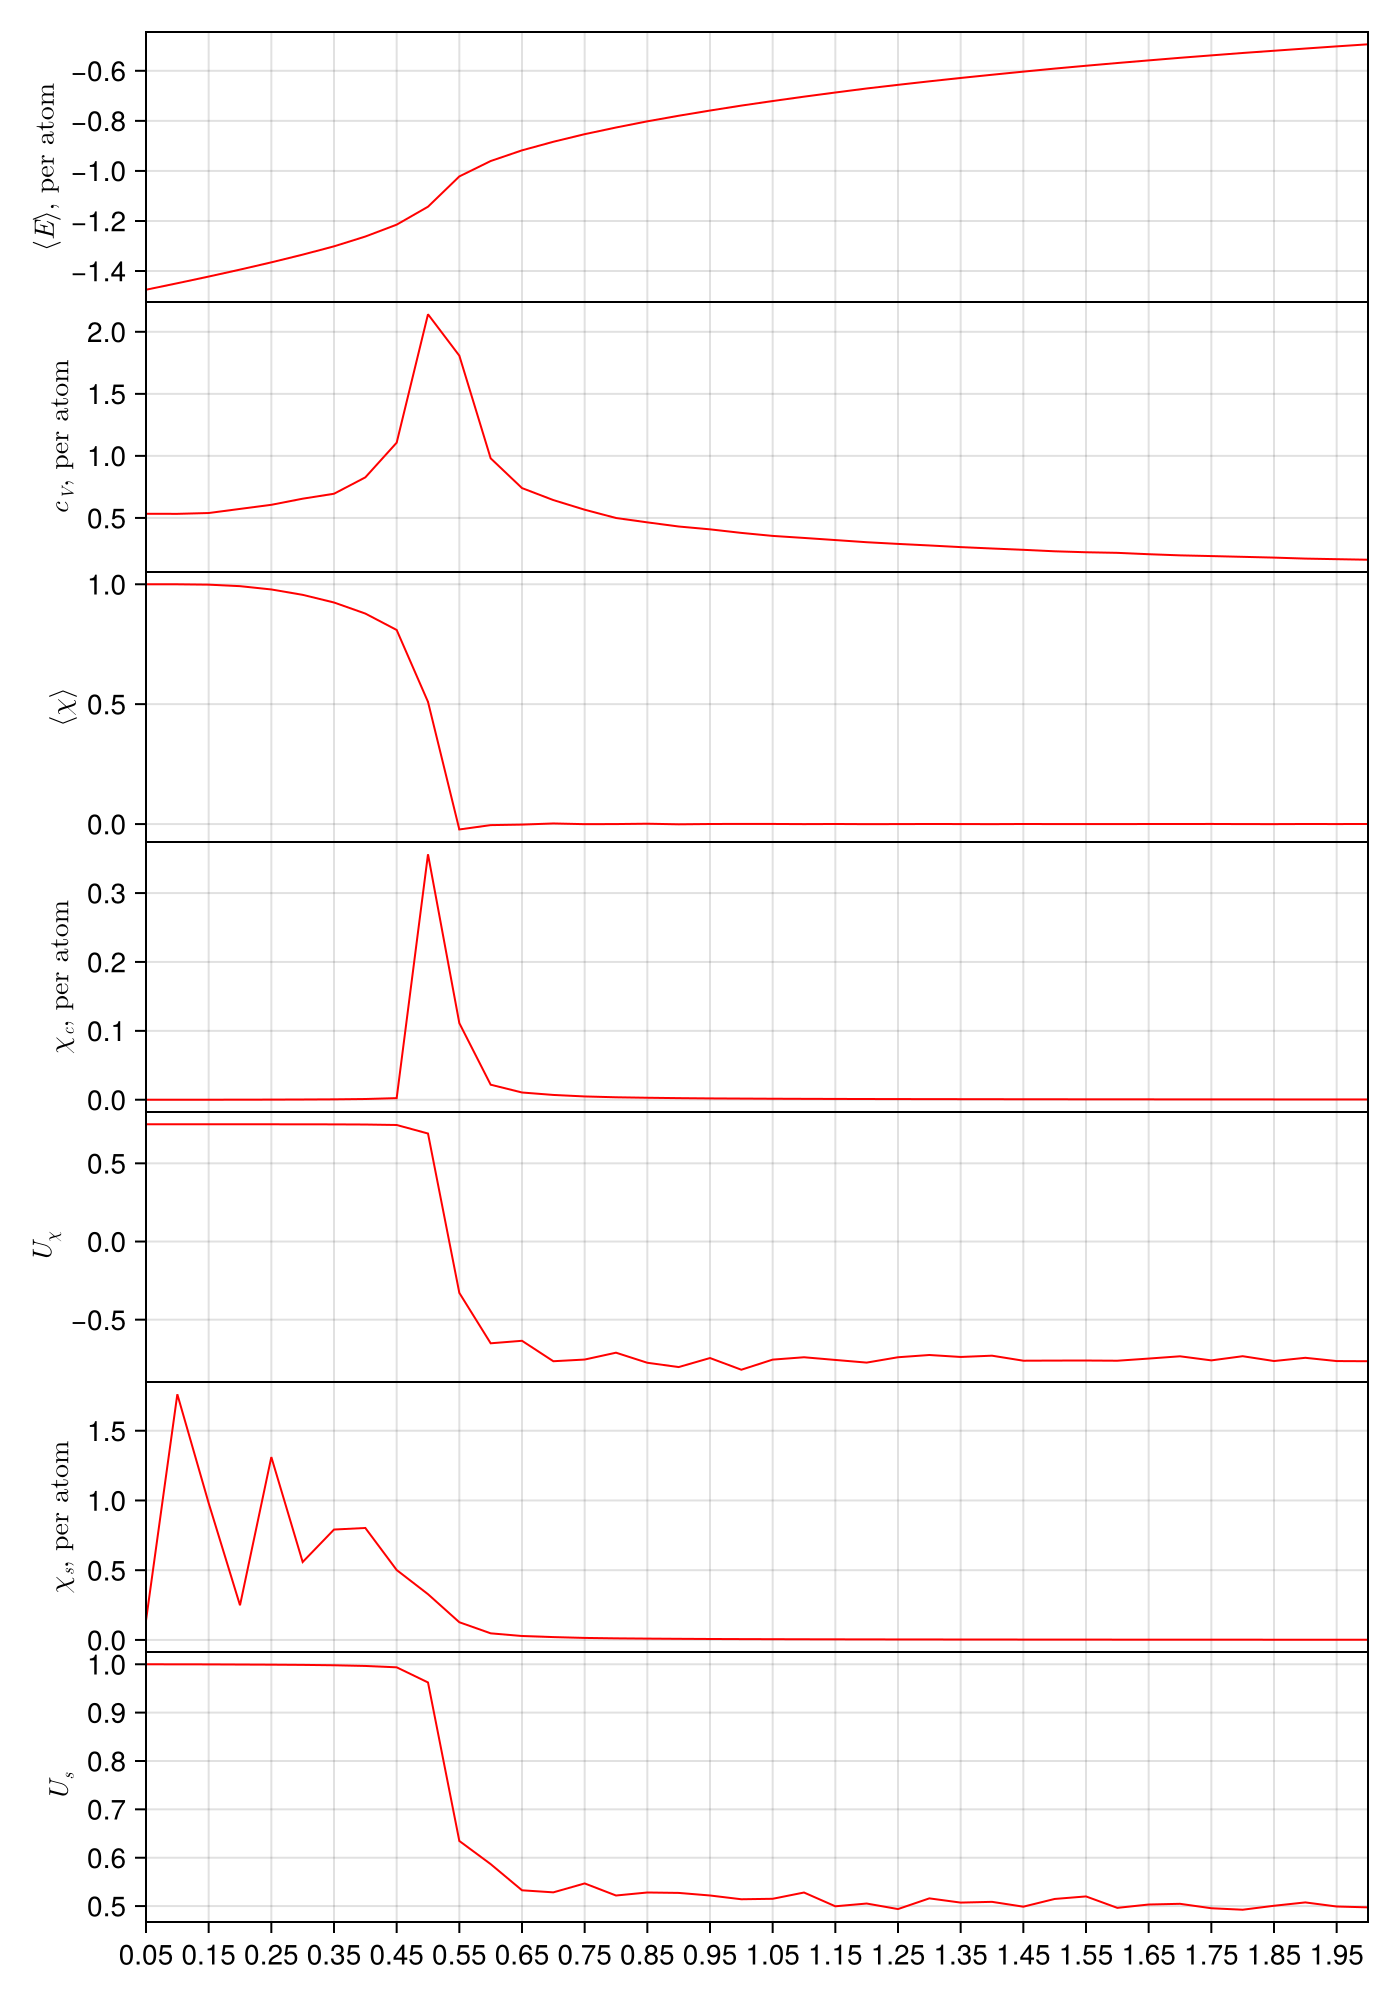

In [116]:
N = L1 * L2
T = collect(T_range)

fig = Figure(size=(700, 1000))

ax1 = Axis(fig[1, 1], ylabel=L"$\langle E\rangle$, per atom", xticklabelsvisible=false, xticksvisible=false, xticks = T[1:2:end])
lines!(ax1, T, E_avg / N, linewidth=1, color=:red)
errorbars!(ax1, T, E_avg / N, E_err / N, linewidth=1, color=:red)

ax2 = Axis(fig[2, 1], ylabel=L"$c_V$, per atom", xticklabelsvisible=false, xticksvisible=false, xticks = T[1:2:end])
linkxaxes!(ax1, ax2)
lines!(ax2, T, cV / N, linewidth=1, color=:red)

ax3 = Axis(fig[3, 1], ylabel=L"$\langle\chi\rangle$", xticklabelsvisible=false, xticksvisible=false, xticks = T[1:2:end])
linkxaxes!(ax2, ax3)
lines!(ax3, T, χ_avg, linewidth=1, color=:red)
errorbars!(ax3, T, χ_avg, χ_err, linewidth=1, color=:red)

ax4 = Axis(fig[4, 1], ylabel=L"$\chi_c$, per atom", xticklabelsvisible=false, xticksvisible=false, xticks = T[1:2:end])
linkxaxes!(ax3, ax4)
lines!(ax4, T, χ_susc / N, linewidth=1, color=:red)

ax5 = Axis(fig[5, 1], ylabel=L"$U_\chi$", xticklabelsvisible=false, xticksvisible=false, xticks = T[1:2:end])
linkxaxes!(ax4, ax5)
lines!(ax5, T, χ_binder, linewidth=1, color=:red)

ax6 = Axis(fig[6, 1], ylabel=L"$\chi_s$, per atom", xticklabelsvisible=false, xticksvisible=false, xticks = T[1:2:end])
linkxaxes!(ax5, ax6)
lines!(ax6, T, m_susc / N, linewidth=1, color=:red)

ax7 = Axis(fig[7, 1], ylabel=L"$U_s$", xticks = T[1:2:end])
linkxaxes!(ax6, ax7)
lines!(ax7, T, m_binder, linewidth=1, color=:red)

xlims!(first(T), last(T))
rowgap!(fig.layout, 0)

fig